# 04 Results: Isolation Forest on the DNS tunnel data (slice 4 and 5)

One notebook, top to bottom: the main setup, the main result, the comparison with simple rules, what the alerts look like as incidents, three checks (alert line and window, robustness and stress tests, errors) and the takeaways. All modelling code is in `src/` (`detector.py`, `evaluation.py`, `baselines.py`, `incidents.py`, `variants.py`, `plots.py`); this notebook only sets things up, calls it and shows the results. Figures are saved in `notebooks/figures/`.

Run time is about 2 to 3 minutes. Needs `data/raw/dns.log` (Canvas download); it builds the features itself, so `python main.py` is not required.

**How to read the numbers.** There is one tunnel session and one benign client, so everything here is optimistic and none of it proves generalisation. ROC and PR AUC do not depend on the alert line; precision, recall and the false positives do. Seeds only vary the random forest, not the data.

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import make_matrix, build_features, feature_sets
from src.prepare import load_raw, prepare
from src.detector import run_detector, DEFAULTS
from src.evaluation import confusion, recall_per_phase, feature_importance, plot_score_distribution
from src.incidents import group_alerts, incident_metrics
from src.baselines import run_rule
from src.variants import slow_tunnel, add_benign_clients, inject_repeats
from src.plots import plot_isolation_view

FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. The main setup and the main result

In [3]:
WINDOW, THRESHOLD, SEEDS = 60, "val_max", list(range(10))
FEATURES = feature_sets(WINDOW)["forced"]

pd.Series({
    "model": f"Isolation Forest, {DEFAULTS['n_estimators']} trees, 256 rows per tree",
    "features": ", ".join(FEATURES),
    "window": f"{WINDOW} s",
    "training": "normal traffic only, before 18:30 UTC: first 80% fits the forest, last 20% sets the alert line",
    "alert line": "highest score on the held-back normal slice (val_max)",
    "test": "everything from 18:30 UTC (contains the tunnel session)",
    "seeds": f"{len(SEEDS)} (0 to {SEEDS[-1]}); mean and spread are reported, never the best seed",
}, name="setup").to_frame()

,setup
model,"Isolation Forest, 300 trees, 256 rows per tree"
features,"name_bytes, uniq_names_60s, uniq_ratio_60s, no..."
window,60 s
training,"normal traffic only, before 18:30 UTC: first 8..."
alert line,highest score on the held-back normal slice (v...
test,everything from 18:30 UTC (contains the tunnel...
seeds,"10 (0 to 9); mean and spread are reported, nev..."


In [4]:
m = make_matrix(session="second", window_s=WINDOW, write=False)
print(m.groupby(["split", "label"]).size().unstack(fill_value=0))


def metrics(scored):
    """Everything we report for one scored table (test rows only)."""
    t = scored[scored.role == "test"]
    return {"roc_auc": roc_auc_score(t.y, t.score), "pr_auc": average_precision_score(t.y, t.score),
            **confusion(t.y, t.alert), **incident_metrics(scored)}


runs = {s: run_detector(m, FEATURES, threshold=THRESHOLD, random_state=s) for s in SEEDS}
main = pd.DataFrame({s: metrics(sc) for s, (sc, info) in runs.items()}).T
COLS = ["roc_auc", "pr_auc", "precision", "recall", "f1", "fpr", "fp", "fn", "false_incidents", "seconds_to_first_alert"]
headline = main[COLS].astype(float).agg(["mean", "std", "min", "max"]).T.round(3)
headline

label  benign  tunnel
split                
test     1609     222
train    1592       0


,mean,std,min,max
roc_auc,0.996,0.000,0.995,0.996
pr_auc,0.993,0.000,0.992,0.994
precision,0.746,0.029,0.693,0.791
recall,0.987,0.001,0.986,0.991
f1,0.850,0.019,0.814,0.878
fpr,0.047,0.007,0.036,0.060
fp,74.900,11.676,58.000,97.000
fn,2.900,0.316,2.000,3.000
false_incidents,3.100,0.316,3.000,4.000
seconds_to_first_alert,0.007,0.000,0.007,0.007


Seed 0 is the default run in `python -m src.detector`; it is shown in detail below, but it is one of ten seeds and not the best.

alert line (seed 0): 0.6876


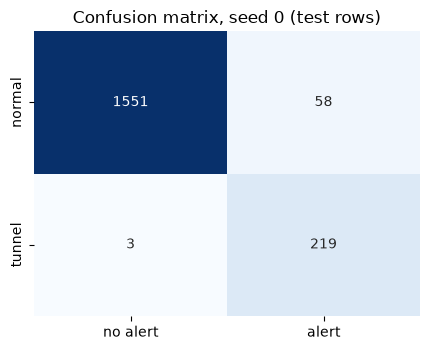

,queries,detected,recall
phase,,,
data,24,24,1.000
encoding_test,9,8,0.889
handshake,3,1,0.333
ping,173,173,1.000
size_probe,13,13,1.000


In [5]:
scored0, info0 = runs[0]
t0 = scored0[scored0.role == "test"]
print(f"alert line (seed 0): {info0['threshold']:.4f}")

c0 = confusion(t0.y, t0.alert)
cm = np.array([[c0["tn"], c0["fp"]], [c0["fn"], c0["tp"]]])
fig, ax = plt.subplots(figsize=(4.4, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["no alert", "alert"], yticklabels=["normal", "tunnel"])
ax.set_title("Confusion matrix, seed 0 (test rows)")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()
recall_per_phase(t0).round(3)

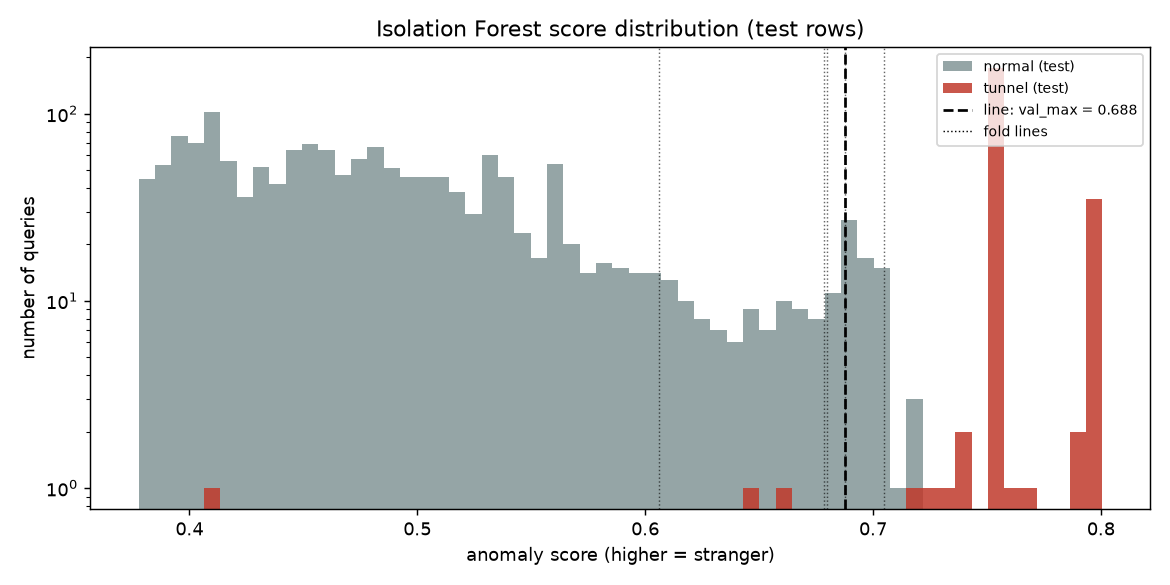

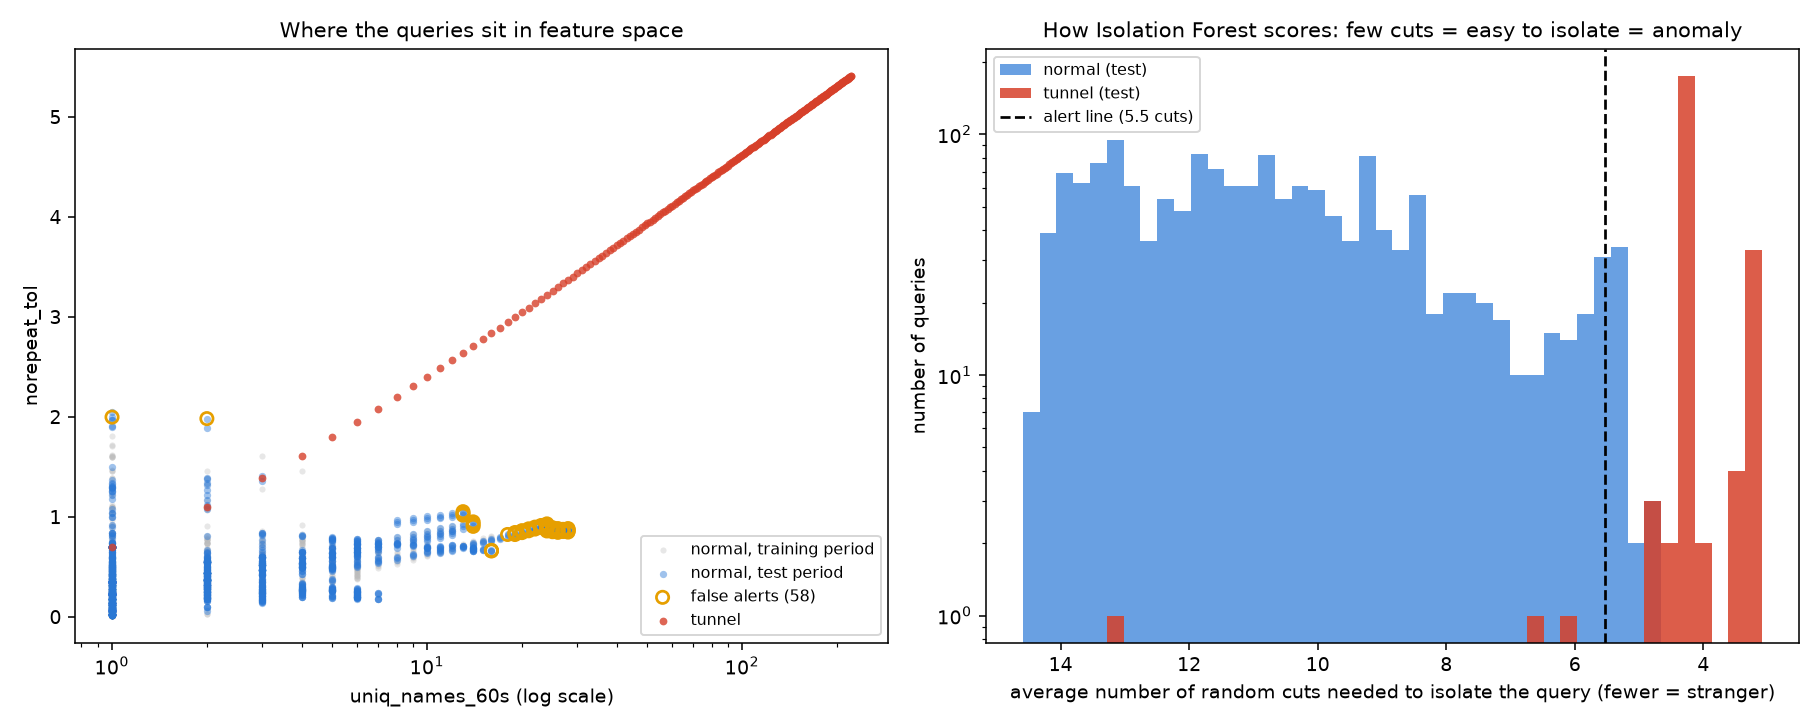

In [6]:
display(Image(filename=str(plot_score_distribution(scored0, info0, FIG / "score_distribution.png"))))
display(Image(filename=str(plot_isolation_view(scored0, info0, FIG / "isolation_forest_view.png"))))

In [7]:
imp = feature_importance(info0["model"], t0[FEATURES], t0.y.to_numpy())
fig, ax = plt.subplots(figsize=(6.5, 2.6))
imp.sort_values().plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("PR AUC drop when the feature is shuffled (explains the model; not used to choose features)")
plt.tight_layout(); plt.savefig(FIG / "feature_importance.png", dpi=150); plt.show()
imp.round(3).to_frame()

,PR AUC drop
uniq_names_60s,0.342
norepeat_tol,0.200
name_bytes,0.007
uniq_ratio_60s,0.004


## 2. Against simple rules

A rule has nothing to fit: it scores each query with one number and alerts when that number is higher than anything seen in normal training traffic. **Unique names** uses `uniq_names_60s`; **name shape** alerts on a longer or more random-looking name than in training. The Isolation Forest row is the mean of the seeds.

In [8]:
rules = {"rule: unique names": run_rule(m, "unique_names", WINDOW),
         "rule: name shape": run_rule(m, "shape", WINDOW)}
rows = {f"Isolation Forest (mean of {len(SEEDS)} seeds)": main[COLS].astype(float).mean()}
for name, sc in rules.items():
    rows[name] = pd.Series(metrics(sc))[COLS]
compare = pd.DataFrame(rows).T.astype(float).round(3)
compare

,roc_auc,pr_auc,precision,recall,f1,fpr,fp,fn,false_incidents,seconds_to_first_alert
Isolation Forest (mean of 10 seeds),0.996,0.993,0.746,0.987,0.850,0.047,74.9,2.9,3.1,0.007
rule: unique names,0.987,0.958,0.798,0.928,0.858,0.032,52.0,16.0,1.0,3.016
rule: name shape,0.617,0.324,0.909,0.180,0.301,0.002,4.0,182.0,2.0,0.008


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))


def add_curves(t, label=None, **kw):
    fpr, tpr, _ = roc_curve(t.y, t.score)
    p, r, _ = precision_recall_curve(t.y, t.score)
    ax[0].plot(fpr, tpr, label=label, **kw)
    ax[1].plot(r, p, label=label, **kw)


for i, (s, (sc, _)) in enumerate(runs.items()):
    add_curves(sc[sc.role == "test"], label=f"Isolation Forest ({len(SEEDS)} seeds)" if i == 0 else None,
               color="#2a78d6", alpha=.3, lw=1.2)
for (name, sc), color in zip(rules.items(), ["#e69f00", "#7f7f7f"]):
    add_curves(sc[sc.role == "test"], label=name, color=color, lw=1.8)
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test rows)")
ax[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (test rows)")
ax[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "roc_pr_curves.png", dpi=150); plt.show()

## 3. The alerts as incidents

Hundreds of alert queries are not hundreds of things to investigate. Alerts of the same client and domain less than 60 seconds apart form one incident (`src/incidents.py`).

In [10]:
inc0 = group_alerts(scored0).assign(
    start=lambda d: pd.to_datetime(d.start, unit="s").dt.strftime("%H:%M:%S"),
    end=lambda d: pd.to_datetime(d.end, unit="s").dt.strftime("%H:%M:%S"))
print("incidents of seed 0:")
display(inc0.round(3))

INC = ["fp", "incidents", "false_incidents", "tunnel_incidents", "false_incidents_per_hour", "seconds_to_first_alert"]
rows = {f"Isolation Forest (mean of {len(SEEDS)} seeds)": main[INC].astype(float).mean()}
for name, sc in rules.items():
    rows[name] = pd.Series(metrics(sc))[INC]
pd.DataFrame(rows).T.astype(float).round(2).rename(columns={"fp": "false alert queries"})

incidents of seed 0:


,client,parent,start,end,alerts,top_score,is_tunnel
0,192.168.179.21,azure.com,18:46:42,18:47:17,2,0.691,False
1,192.168.179.21,yahoo.com,18:50:29,18:52:00,50,0.717,False
2,10.0.2.30,pirate.sea,18:50:50,18:51:15,219,0.801,True
3,192.168.179.21,yahoodns.net,18:51:04,18:52:00,6,0.695,False


,false alert queries,incidents,false_incidents,tunnel_incidents,false_incidents_per_hour,seconds_to_first_alert
Isolation Forest (mean of 10 seeds),74.9,4.1,3.1,1.0,4.66,0.01
rule: unique names,52.0,2.0,1.0,1.0,1.50,3.02
rule: name shape,4.0,3.0,2.0,1.0,3.01,0.01


## 4. Check 1: the alert line and the window

The ranking hardly changes with the window or the threshold method, but the number of false positives does. Mean over seeds of the false positives and the recall for every combination. `val_max` at 60 s is the default; the others are for comparison, not for choosing on these test rows.

In [11]:
THRESHOLDS = ["val_max", "val_p995", "val_p99", "tukey_val", "tukey_train", "folds_median", "folds_max"]
rows = []
for w in (60, 300, 900):
    mw = make_matrix(session="second", window_s=w, write=False)
    fw = feature_sets(w)["forced"]
    for s in SEEDS:
        sc, info = run_detector(mw, fw, random_state=s)
        t = sc[sc.role == "test"]
        for th in THRESHOLDS:
            cc = confusion(t.y, t.score > info["candidates"][th])
            rows.append({"window": w, "threshold": th, "seed": s, "fp": cc["fp"], "recall": cc["recall"],
                         "roc_auc": roc_auc_score(t.y, t.score), "pr_auc": average_precision_score(t.y, t.score)})
sens = pd.DataFrame(rows)
fp_mean = sens.pivot_table(index="threshold", columns="window", values="fp").reindex(THRESHOLDS)
fp_sd = sens.pivot_table(index="threshold", columns="window", values="fp", aggfunc="std").reindex(THRESHOLDS)
rec_mean = sens.pivot_table(index="threshold", columns="window", values="recall").reindex(THRESHOLDS)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(fp_mean, annot=True, fmt=".0f", cmap="Oranges", ax=ax[0], cbar=False)
ax[0].set_title("false positives (mean over seeds)")
sns.heatmap(rec_mean, annot=True, fmt=".2f", cmap="Greens", vmin=0.4, vmax=1, ax=ax[1], cbar=False)
ax[1].set_title("recall (mean over seeds)")
for a in ax:
    a.set_ylabel(""); a.set_xlabel("window (s)")
plt.tight_layout(); plt.savefig(FIG / "threshold_by_window.png", dpi=150); plt.show()
print("ranking (mean over seeds and thresholds), per window:")
sens.groupby("window")[["roc_auc", "pr_auc"]].mean().round(3)

ranking (mean over seeds and thresholds), per window:


,roc_auc,pr_auc
window,,
60,0.996,0.993
300,0.996,0.993
900,0.997,0.995


In [12]:
print("mean over seeds: false positives and recall per alert line and window")
display(pd.concat({"false positives": fp_mean.round(0), "recall": rec_mean.round(3)}, axis=1))
print("spread of the false positives over seeds (standard deviation):")
fp_sd.round(1)

mean over seeds: false positives and recall per alert line and window


false positives               recall              
window                   60     300    900    60     300    900
threshold                                                      
val_max                 75.0    3.0    4.0  0.987  0.986  0.986
val_p995                82.0    8.0   10.0  0.987  0.986  0.986
val_p99                100.0   20.0   14.0  0.989  0.986  0.986
tukey_val              100.0    0.0   25.0  0.991  0.977  0.989
tukey_train            181.0  162.0  191.0  0.995  0.995  0.995
folds_median            76.0    9.0    8.0  0.987  0.986  0.986
folds_max                4.0    0.0    0.0  0.983  0.889  0.571

spread of the false positives over seeds (standard deviation):


window,60,300,900
threshold,,,
val_max,11.7,2.7,2.4
val_p995,11.2,4.5,5.4
val_p99,7.3,12.9,4.5
tukey_val,11.2,0.0,11.6
tukey_train,9.3,7.6,8.4
folds_median,9.7,4.8,2.7
folds_max,8.1,0.0,0.0


## 5. Check 2: robustness and stress tests

The same model and settings (60 s, `val_max`, 5 seeds) on other versions of the data, next to the unique-names rule. The simulations are built from this one capture (`src/variants.py`); they test robustness, they do not prove generalisation.

- **strict:** the other copy of the tunnel session, with only 244 quiet rows to train on (a load change between training and test)
- **slow tunnel:** the same queries, 20 or 60 times further apart (60 times is about 25 minutes)
- **10 benign hosts:** the normal traffic copied onto more hosts that share domains
- **one repeated tunnel name:** a retransmission, or an attacker repeating a name

In [13]:
STRESS_SEEDS = SEEDS[:5]
prep = prepare(load_raw(), session="second")
cases = {
    "main (reference)": m,
    "strict: other copy, 244 training rows": make_matrix(session="first", window_s=WINDOW, write=False),
    "slow tunnel x20": build_features(slow_tunnel(prep, 20), WINDOW),
    "slow tunnel x60": build_features(slow_tunnel(prep, 60), WINDOW),
    "10 benign hosts": build_features(add_benign_clients(prep, n_extra=9, seed=0), WINDOW),
    "one repeated tunnel name": build_features(inject_repeats(prep, n=1), WINDOW),
}
RCOLS = ["roc_auc", "pr_auc", "precision", "recall", "fp", "false_incidents", "seconds_to_first_alert"]
rows = []
for name, mc in cases.items():
    ms = pd.DataFrame([metrics(run_detector(mc, FEATURES, threshold=THRESHOLD, random_state=s)[0]) for s in STRESS_SEEDS])
    rows.append({"case": name, "model": "Isolation Forest", **ms[RCOLS].astype(float).mean().to_dict()})
    rows.append({"case": name, "model": "rule: unique names", **pd.Series(metrics(run_rule(mc, "unique_names", WINDOW)))[RCOLS].astype(float).to_dict()})
robust = pd.DataFrame(rows).set_index(["case", "model"]).round(3)
robust

roc_auc  pr_auc  precision  recall     fp  false_incidents  seconds_to_first_alert
case                                  model                                                                                                 
main (reference)                      Isolation Forest      0.996   0.993      0.747   0.987   75.0              3.0                   0.007
                                      rule: unique names    0.987   0.958      0.798   0.928   52.0              1.0                   3.016
strict: other copy, 244 training rows Isolation Forest      0.992   0.983      0.182   0.989  985.4            117.4                   0.007
                                      rule: unique names    0.989   0.954      0.301   0.982  506.0             30.0                   0.007
slow tunnel x20                       Isolation Forest      0.995   0.989      0.746   0.983   75.0              3.0                   0.144
                                      rule: unique names    0.953   0.874      0.772   0.793   52.0              1.0                 261.984
slow tunnel x60                       Isolation Forest      0.995   0.989      0.746   0.983   75.0              3.0                   0.433
                                      rule: unique names    0.931   0.861      0.772   0.793   52.0              1.0                 785.952
10 benign hosts                       Isolation Forest      0.996   0.988      0.357   0.986  426.4             18.8                   0.007
                                      rule: unique names    0.987   0.906      0.284   0.928  520.0             10.0                   3.016
one repeated tunnel name              Isolation Forest      0.996   0.993      0.748   0.987   75.0              3.0                   0.007
                                      rule: unique names    0.987   0.958      0.799   0.928   52.0              1.0                   3.016

In [14]:
pr = robust["pr_auc"].unstack("model").loc[list(cases)]
fig, ax = plt.subplots(figsize=(8, 3.6))
pr.plot.barh(ax=ax, color=["#2a78d6", "#e69f00"]); ax.invert_yaxis()
ax.set_xlabel("PR AUC (test rows)"); ax.set_ylabel(""); ax.set_xlim(0, 1.05)
plt.tight_layout(); plt.savefig(FIG / "stress_tests_pr_auc.png", dpi=150); plt.show()

## 6. Check 3: the errors

Which normal queries raise alerts, and which tunnel queries are missed (seed 0, default alert line).

In [15]:
def clock(ts):
    d = pd.to_datetime(ts, unit="s")
    return d.dt.strftime("%H:%M:%S") if isinstance(d, pd.Series) else d.strftime("%H:%M:%S")


fp = t0[(t0.alert == 1) & (t0.y == 0)]
print(f"{len(fp)} false alert queries; per domain:")
print(fp.parent.value_counts().to_string())
train_part = scored0[scored0.role != "test"]
normal_test = t0[t0.y == 0]
print(f"\nlargest unique-names count in training: {train_part.uniq_names_60s.max():.0f}; "
      f"normal test rows above it: {(normal_test.uniq_names_60s > train_part.uniq_names_60s.max()).sum()}")
print(f"false alerts between {clock(fp.ts.min())} and {clock(fp.ts.max())} UTC; "
      f"{(fp.parent == 'yahoo.com').sum()} of them are yahoo.com")

show = ["time", "parent", "score"] + FEATURES
print("\ntop 10 false alerts:")
display(fp.assign(time=clock(fp.ts)).sort_values("score", ascending=False).head(10)[show].round(3))
fn = t0[(t0.alert == 0) & (t0.y == 1)]
print("missed tunnel queries:")
display(fn.assign(time=clock(fn.ts))[["time", "phase", "score"] + FEATURES].round(3))

58 false alert queries; per domain:
parent
yahoo.com       50
yahoodns.net     6
azure.com        2

largest unique-names count in training: 16; normal test rows above it: 52
false alerts between 18:46:42 and 18:52:00 UTC; 50 of them are yahoo.com

top 10 false alerts:


,time,parent,score,name_bytes,uniq_names_60s,uniq_ratio_60s,norepeat_tol
1949,18:50:30,yahoo.com,0.717,34,25.0,0.255,0.881
1948,18:50:30,yahoo.com,0.717,34,25.0,0.258,0.889
1950,18:50:30,yahoo.com,0.717,34,25.0,0.253,0.873
2351,18:51:03,yahoo.com,0.708,13,27.0,0.241,0.851
1935,18:50:30,yahoo.com,0.705,13,24.0,0.258,0.882
1934,18:50:30,yahoo.com,0.704,13,24.0,0.261,0.891
1933,18:50:30,yahoo.com,0.704,13,24.0,0.264,0.900
2019,18:50:33,yahoo.com,0.703,14,26.0,0.241,0.843
1905,18:50:29,yahoo.com,0.702,30,20.0,0.263,0.860
1906,18:50:29,yahoo.com,0.702,30,20.0,0.260,0.850


missed tunnel queries:


,time,phase,score,name_bytes,uniq_names_60s,uniq_ratio_60s,norepeat_tol
2246,18:50:50,handshake,0.408,22,1.0,1.0,0.693
2247,18:50:50,handshake,0.644,43,2.0,1.0,1.099
2248,18:50:50,encoding_test,0.661,17,3.0,1.0,1.386


In [16]:
tt = t0.assign(dt=pd.to_datetime(t0.ts, unit="s"))
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.scatter(tt[tt.y == 0].dt, tt[tt.y == 0].score, s=6, c="#2a78d6", alpha=.5, label="normal")
ax.scatter(tt[tt.y == 1].dt, tt[tt.y == 1].score, s=8, c="#d6402a", label="tunnel")
ax.axhline(info0["threshold"], color="k", ls="--", lw=1.2, label="alert line")
ax.set_ylabel("anomaly score"); ax.set_xlabel("time (UTC)"); ax.legend(fontsize=8, loc="center left")
plt.tight_layout(); plt.savefig(FIG / "score_timeline.png", dpi=150); plt.show()

## 7. Takeaways

**The main result (section 1, default setup, mean over 10 seeds).**
- The tunnel is ranked almost perfectly: ROC AUC 0.996 and PR AUC 0.993, with almost no spread between seeds.
- At the default alert line recall is 0.987. Only the first 2 to 3 queries of the session are missed (handshake and encoding-test queries; seed 0 misses 3); the first alert comes 7 milliseconds into the session. Precision is 0.746 (0.69 to 0.79 over seeds) and F1 0.850, with 75 false alert queries on average (58 to 97).
- Grouped into incidents (section 3), the tunnel is one incident of 219 alerts and the false alerts are about 3 incidents (seed 0: `yahoo.com` 50 alerts, `yahoodns.net` 6, `azure.com` 2). The 58 false positives of seed 0 are the best of the ten seeds.
- The model leans on `uniq_names_60s` (PR AUC drop 0.342 when shuffled) and `norepeat_tol` (0.200). `name_bytes` (0.007) and `uniq_ratio_60s` (0.004) hardly matter here.

**Against simple rules (section 2).**
- A rule on unique names alone is competitive at its operating point: F1 0.858 against 0.850, precision 0.798, recall 0.928, and only 1 false incident. The forest ranks better (PR AUC 0.993 against 0.958) and misses less (recall 0.987).
- A rule on name length or randomness finds only the data and probe queries (recall 0.18, ROC AUC 0.617), which confirms that single-query checks are not enough.

**Where the forest is clearly better: slow tunnels (section 5).** With the tunnel 60 times slower (about 25 minutes), the forest keeps PR AUC 0.989 and alerts within 0.5 seconds of the session start, because `norepeat_tol` has no time window. The unique-names rule falls to recall 0.793 and needs 262 to 786 seconds to alert.

**What the alert line does (sections 4 and 6).**
- The ranking does not depend on the window (PR AUC 0.993, 0.993, 0.995 for 60, 300 and 900 s), but the number of false positives does: with `val_max` 75 at 60 s against 3 and 4 at 300 and 900 s. The `folds_max` line looks best at 60 s (4 false positives) but loses recall at longer windows (0.889 at 300 s, 0.571 at 900 s). Do not choose a window or an alert line because of these counts: they were seen on the test rows.
- The false alerts come from one busy normal period: 50 of the 58 false alert queries of seed 0 are `yahoo.com` between 18:46 and 18:52. Training never saw more than 16 unique names in 60 s, and 52 normal test rows exceed that. The detector has no way to know that this burst is normal; this is the main limit of a model trained on a short, calm period of normal traffic.

**Robustness (section 5).** With only 244 quiet training rows (strict variant) the alert line is far too low: 985 false positives (precision 0.18), while the ranking holds (PR AUC 0.983). With 10 benign hosts there are about 19 false incidents and precision falls to 0.36. A repeated tunnel name changes nothing.

**What this does not show.** One tunnel session and one benign client, so all numbers are optimistic and say nothing about other tunnels or networks. The variants are simulations built from this one capture. The seeds vary the random forest only, not the data. Comparing alert lines on the test rows was done to explain the results, not to choose the default. Not covered: tunnels that rotate domains, tunnels with other record types, a second dataset, and a live setting where normal traffic changes over time and the alert line needs recalibrating.

**One sentence.** DNS tunnelling is found because it cannot avoid creating many new names under one domain; the Isolation Forest ranks it almost perfectly from a few such features, and how many false alerts result depends on the alert line and on how representative the normal training traffic is.
